# When Several Minds Help

*The Mathematics of Machine Intelligence · Chapter 23*

Count how much your guessers' mistakes overlap before counting heads.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask for the guesses or scores, how each was produced, whether the members learned from the same sources, and how lopsided the errors look. Then pick the card: the variance formula and effective size for how much an average will vary, a median or geometric mean when a few guesses are wildly off, inverse-variance weighting when one source is independent of the rest, and a check on whether the vote's members share the same wrong answer. Report the pooled answer, the effective size under a stated correlation, and the assumption that would break it.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 23, When Several Minds Help: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'
STYLES = [('dotted', GREY), ('solid', TEAL), ('dashed', TERRA), ('dashdot', GOLD)]

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def gaussian(x, mean, var):
    return np.exp(-0.5 * (x - mean) ** 2 / var) / math.sqrt(2 * math.pi * var)

def average_variance(n, rho, sigma2=1.0):
    """Variance of the mean of n equally weighted errors with common variance and pairwise correlation rho."""
    if n < 1:
        raise ValueError('A panel needs at least one member.')
    return sigma2 * ((1 - rho) / n + rho)

def panel_means(n, rho, panels_count, seed):
    """Seeded panels: each error is a shared part plus a private part, so pairs correlate at rho."""
    rng = np.random.default_rng(seed)
    shared = rng.standard_normal((panels_count, 1))
    private = rng.standard_normal((panels_count, n))
    errors = math.sqrt(rho) * shared + math.sqrt(1 - rho) * private
    return errors.mean(axis=1)
D01_PANELS = 4000

def average_picture(n=4, rho=0.2):
    exact = average_variance(n, rho)
    unrelated = 1.0 / n
    floor = rho
    seed = 2300 + 10 * n + int(round(rho * 10))
    means = panel_means(n, rho, D01_PANELS, seed)
    simulated = float(means.var())
    fig, ax = panels()
    bins = np.linspace(-3.5, 3.5, 36)
    ax[0].hist(means, bins=bins, density=True, color=TEAL, alpha=0.55, edgecolor='white', label=f'{D01_PANELS} simulated panels')
    x = np.linspace(-3.5, 3.5, 500)
    ax[0].plot(x, gaussian(x, 0, exact), color=NAVY, linewidth=2.5, label='bell curve from the formula')
    ax[0].plot(x, gaussian(x, 0, unrelated), color=GREY, linewidth=1.6, linestyle='dashed', label='if errors were unrelated')
    ax[0].set(xlabel="error of the panel's average", ylabel='density', title=f'{n} guessers, correlation {sig(rho)}', xlim=(-3.5, 3.5))
    ax[0].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    grid = np.arange(1, 101)
    for (style, colour), other in zip(STYLES, [0.0, 0.2, 0.5, 1.0]):
        chosen = other == rho
        ax[1].plot(grid, [average_variance(g, other) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'correlation {other:g}')
    ring(ax[1], n, exact)
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_xticks([1, 2, 5, 10, 20, 50, 100])
    ax[1].set_xticklabels(['1', '2', '5', '10', '20', '50', '100'])
    ax[1].set_yticks([0.01, 0.1, 1])
    ax[1].set_yticklabels(['0.01', '0.1', '1'])
    ax[1].set(xlabel='number of guessers', ylabel='error variance of the average', title='Shared error sets a floor', ylim=(0.007, 1.3))
    ax[1].legend(fontsize=8, loc='lower left')
    metrics = {'Variance of the average': sig(exact), 'Variance if errors were unrelated': sig(unrelated), 'Floor, however many are added': sig(floor), f'Simulated variance ({D01_PANELS} panels)': sig(simulated)}
    summary = f'With {n} guessers, each with error variance 1 and pairwise error correlation {sig(rho)}, the average has error variance {sig(exact)}, against {sig(unrelated)} if the errors were unrelated. Adding guessers can never take it below {sig(floor)}.'
    calc = f'Var = sigma^2 x ((1 - rho)/n + rho) = ((1 - {sig(rho)})/{n} + {sig(rho)}) = {sig(exact)}. Unrelated errors: 1/{n} = {sig(unrelated)}. Floor = rho = {sig(floor)}. The simulation (seed {seed}) built each error from a shared part and a private part and gave {sig(simulated)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def effective_size(n, rho):
    if n < 1:
        raise ValueError('A panel needs at least one member.')
    return n / (1 + (n - 1) * rho)

def effective_picture(n=787, rho=0.021):
    worth = effective_size(n, rho)
    ceiling = None if rho == 0 else 1 / rho
    grid = np.unique(np.round(np.geomspace(1, 3000, 160)).astype(int))
    fig, ax = panels()
    ax[0].plot(grid, [effective_size(g, rho) for g in grid], color=NAVY, linewidth=3, label='effective panel size')
    ax[0].plot(grid, grid, color=GREY, linewidth=1.2, linestyle='dotted', label='headcount')
    if ceiling is not None:
        ax[0].axhline(ceiling, color=TERRA, linewidth=1.5, linestyle='dashed')
        tag(ax[0], 2.2, ceiling * 1.2, f'ceiling 1/rho = {sig(ceiling)}', color=TERRA, ha='left', va='bottom')
    ring(ax[0], n, worth)
    ax[0].set_xscale('log')
    ax[0].set_yscale('log')
    ax[0].set_xticks([1, 10, 100, 1000])
    ax[0].set_xticklabels(['1', '10', '100', '1000'])
    ax[0].set_yticks([1, 10, 100, 1000])
    ax[0].set_yticklabels(['1', '10', '100', '1000'])
    ax[0].set(xlabel='number of guessers', ylabel='independent guessers it is worth', title=f'Correlation {sig(rho)}', ylim=(0.8, 4000))
    ax[0].legend(fontsize=8, loc='upper left')
    for (style, colour), other in zip(STYLES, [0.0, 0.021, 0.05, 0.12]):
        chosen = other == rho
        ax[1].plot(grid, [effective_size(g, other) / g for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'correlation {other:g}')
    ring(ax[1], n, worth / n)
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_xticks([1, 10, 100, 1000])
    ax[1].set_xticklabels(['1', '10', '100', '1000'])
    ax[1].set_yticks([0.001, 0.01, 0.1, 1])
    ax[1].set_yticklabels(['0.001', '0.01', '0.1', '1'])
    ax[1].set(xlabel='number of guessers', ylabel='worth per head', title='Each added head is worth less', ylim=(0.0003, 1.6))
    ax[1].legend(fontsize=8, loc='lower left')
    metrics = {'Effective panel size': sig(worth), 'Ceiling as the panel grows': 'none (errors unrelated, so no ceiling)' if ceiling is None else sig(ceiling), 'Worth per head': sig(worth / n), 'Variance of the average (sigma^2 = 1)': sig(average_variance(n, rho))}
    if ceiling is None:
        tail = 'With unrelated errors there is no ceiling, and each head counts fully.'
    else:
        tail = f'No panel of this kind can be worth more than {sig(ceiling)}.'
    summary = f'{n} guessers whose errors correlate at {sig(rho)} are worth {sig(worth)} independent ones, or {sig(worth / n)} of a head each. {tail}'
    calc = f'n_eff = n/(1 + (n - 1) rho) = {n}/(1 + {n - 1} x {sig(rho)}) = {n}/{sig(1 + (n - 1) * rho)} = {sig(worth)}. ' + ('No ceiling: rho is 0.' if ceiling is None else f'Ceiling = 1/rho = {sig(ceiling)}.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TRUE_COUNT = 198
SAMPLE_SIZE = 144
SAMPLE_SEED = 2011

def base_guesses(seed=SAMPLE_SEED, size=SAMPLE_SIZE):
    """Constructed bulk of guesses: log10 guesses normal around 190 with sd 0.3 (a factor of 2 either way)."""
    rng = np.random.default_rng(seed)
    return 10 ** (math.log10(190) + 0.3 * rng.standard_normal(size))

def contaminated(fraction, factor, seed=SAMPLE_SEED, size=SAMPLE_SIZE):
    guesses = base_guesses(seed, size).copy()
    k = int(round(fraction * size))
    guesses[:k] *= factor
    return (guesses, k)

def three_averages(guesses):
    return {'mean': float(np.mean(guesses)), 'median': float(np.median(guesses)), 'geometric': float(math.exp(np.mean(np.log(guesses))))}

def average_choice_picture(fraction=0.05, factor=100):
    guesses, k = contaminated(fraction, factor)
    avg = three_averages(guesses)
    fig, ax = panels()
    rng = np.random.default_rng(5)
    ax[0].scatter(guesses, -0.9 + 0.5 * rng.random(len(guesses)), s=10, color=GREY, alpha=0.6, zorder=2)
    rows = [('arithmetic mean', avg['mean'], TERRA), ('geometric mean', avg['geometric'], TEAL), ('median', avg['median'], NAVY)]
    for i, (name, value, colour) in enumerate(rows):
        ax[0].plot([value], [i], marker='o', markersize=10, color=colour, zorder=4)
        tag(ax[0], value * 1.35, i, sig(value, 4), va='center', ha='left', color=colour)
    ax[0].axvline(TRUE_COUNT, color=DARK_GOLD, linewidth=1.8, linestyle='dashed')
    tag(ax[0], TRUE_COUNT, 2.6, f'true {TRUE_COUNT}', color=DARK_GOLD, va='center')
    ax[0].set_xscale('log')
    ax[0].set_yticks([-0.65, 0, 1, 2])
    ax[0].set_yticklabels(['each guess', 'arithmetic mean', 'geometric mean', 'median'], fontsize=9)
    ax[0].set(xlabel='guess (log scale)', title=f'{k} of {SAMPLE_SIZE} guesses multiplied by {factor:g}', ylim=(-1.1, 3.0), xlim=(20, 60000))
    fracs = [0, 0.02, 0.05, 0.1]
    for (style, colour), other in zip(STYLES[1:], [10, 100, 1000]):
        chosen = other == factor
        curve = [three_averages(contaminated(f, other)[0])['mean'] / TRUE_COUNT for f in fracs]
        ax[1].plot([100 * f for f in fracs], curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, marker='o', markersize=4, label=f'mean, outliers x{other:g}')
    ax[1].plot([100 * f for f in fracs], [three_averages(contaminated(f, factor)[0])['median'] / TRUE_COUNT for f in fracs], color=GREY, linewidth=1.8, linestyle='dotted', label='median (selected size)')
    ring(ax[1], 100 * fraction, avg['mean'] / TRUE_COUNT)
    ax[1].axhline(1, color=DARK_GOLD, linewidth=1, linestyle='dashed')
    ax[1].set_yscale('log')
    ax[1].set_yticks([0.5, 1, 3, 10, 30, 100])
    ax[1].set_yticklabels(['0.5', '1', '3', '10', '30', '100'])
    ax[1].set(xlabel='percent of guesses with the wrong size class', ylabel='average divided by the true count', title='One tail drags the plain mean', ylim=(0.5, 120))
    ax[1].legend(fontsize=8, loc='upper left')
    metrics = {'Arithmetic mean': sig(avg['mean'], 4), 'Geometric mean': sig(avg['geometric'], 4), 'Median': sig(avg['median'], 4), 'True count': TRUE_COUNT}
    summary = f"With {k} of {SAMPLE_SIZE} constructed guesses multiplied by {factor:g}, the arithmetic mean is {sig(avg['mean'], 4)}, {sig(avg['mean'] / TRUE_COUNT)} times the true {TRUE_COUNT}. The geometric mean, {sig(avg['geometric'], 4)}, and the median, {sig(avg['median'], 4)}, move much less."
    calc = f"Bulk: {SAMPLE_SIZE} guesses with log10 normal, center log10(190), sd 0.3 (seed {SAMPLE_SEED}). The first {k} are multiplied by {factor:g}. Geometric mean = exp(mean of ln guesses) = {sig(avg['geometric'], 4)}. Mean {sig(avg['mean'], 4)}, median {sig(avg['median'], 4)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
GROUP_SIZE = 12
GROUP_SEED = 2012

def group_log_guesses(seed=GROUP_SEED, size=GROUP_SIZE):
    """Constructed session: log10 guesses with a low bias of 0.25 and sd 0.4 around the true log10 count."""
    rng = np.random.default_rng(seed)
    return math.log10(TRUE_COUNT) - 0.25 + 0.4 * rng.standard_normal(size)

def pull_toward_mean(logs, pull, rounds):
    """Every round, each member moves the fraction pull of the way to the current crowd mean (in logs)."""
    out = np.array(logs, dtype=float)
    for _ in range(rounds):
        out = out + pull * (out.mean() - out)
    return out

def miss_decomposition(logs, truth_log):
    individual = float(np.mean((logs - truth_log) ** 2))
    crowd = float((logs.mean() - truth_log) ** 2)
    spread = float(np.mean((logs - logs.mean()) ** 2))
    return (individual, crowd, spread)

def pull_picture(pull=0.5, rounds=3):
    truth_log = math.log10(TRUE_COUNT)
    before = group_log_guesses()
    after = pull_toward_mean(before, pull, rounds)
    ind0, crowd0, spread0 = miss_decomposition(before, truth_log)
    ind1, crowd1, spread1 = miss_decomposition(after, truth_log)
    fig, ax = panels()
    for y, values, name, colour in [(1, 10 ** before, 'first guesses', GREY), (0, 10 ** after, f'after {rounds} round(s)', TEAL)]:
        ax[0].scatter(values, [y] * len(values), s=34, color=colour, zorder=3, alpha=0.85)
        ax[0].text(18, y + 0.22, name, fontsize=9, color=colour, va='bottom')
    ax[0].axvline(TRUE_COUNT, color=DARK_GOLD, linewidth=1.8, linestyle='dashed')
    ax[0].axvline(10 ** before.mean(), color=NAVY, linewidth=1.8)
    tag(ax[0], TRUE_COUNT * 1.07, 1.75, 'true', color=DARK_GOLD, ha='left', fontsize=9)
    tag(ax[0], 10 ** before.mean() * 0.93, 1.45, 'crowd mean', color=NAVY, ha='right', fontsize=9)
    ax[0].set_xscale('log')
    ax[0].set_yticks([])
    ax[0].set(xlabel='guess (log scale)', title='The crowd mean stays; the members converge', ylim=(-0.5, 2.1), xlim=(15, 3000))
    grid = np.linspace(0, 0.95, 60)
    for (style, colour), other in zip(STYLES[1:], [1, 3, 5]):
        chosen = other == rounds
        curve = [miss_decomposition(pull_toward_mean(before, g, other), truth_log)[0] for g in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'{other} round(s)')
    ax[1].axhline(crowd0, color=TERRA, linewidth=1.6, linestyle='dashed')
    tag(ax[1], 0.93, crowd0 - 0.004, "crowd's own squared miss", color=TERRA, ha='right', va='top', fontsize=9)
    ring(ax[1], pull, ind1)
    ax[1].set(xlabel='fraction of the way each member moves per round', ylabel='average squared miss (log10 units)', title='Average individual miss falls', ylim=(0, ind0 * 1.12))
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {'Average individual squared miss, before': sig(ind0), 'Average individual squared miss, after': sig(ind1), "Crowd's squared miss (unchanged)": sig(crowd1), 'Disagreement among members, after': sig(spread1)}
    summary = f"Each of {GROUP_SIZE} constructed guessers moves {sig(pull)} of the way to the group's log average, {rounds} time(s). The average squared miss falls from {sig(ind0)} to {sig(ind1)}, while the crowd's own squared miss stays {sig(crowd1)}."
    calc = f"Average squared miss = crowd's squared miss + disagreement. Before: {sig(ind0)} = {sig(crowd0)} + {sig(spread0)}. After: {sig(ind1)} = {sig(crowd1)} + {sig(spread1)}. Disagreement shrinks by (1 - {sig(pull)})^{2 * rounds} = {sig((1 - pull) ** (2 * rounds))}. Logs are base 10; seed {GROUP_SEED}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def panel_variance(n, rho, sigma2=1.0):
    return average_variance(n, rho, sigma2)

def with_independent_check(panel_var, check_var):
    """Inverse-variance weighting of two unbiased estimates whose errors are unrelated."""
    return 1 / (1 / panel_var + 1 / check_var)

def check_picture(n=9, rho=0.4, check_var=1.0):
    base = panel_variance(n, rho)
    bigger = panel_variance(n + 1, rho)
    combined = with_independent_check(base, check_var)
    w_check = 1 / check_var / (1 / base + 1 / check_var)
    fig, ax = panels()
    labels = [f'panel of {n}', f'panel of {n + 1}', 'check alone', f'panel of {n}\n+ check']
    values = [base, bigger, check_var, combined]
    bars = ax[0].bar(labels, values, color=[TEAL, TEAL, GREY, NAVY], width=0.6)
    for bar, v in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + max(values) * 0.02, sig(v), va='bottom')
    ax[0].set(ylabel='error variance of the answer', title='Another look-alike or a different source?', ylim=(0, max(values) * 1.25))
    ax[0].tick_params(axis='x', labelsize=8)
    grid = np.arange(1, 61)
    for (style, colour), other in zip(STYLES[1:], [0.2, 0.4, 0.6]):
        chosen = other == rho
        ax[1].plot(grid, [panel_variance(g, other) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'correlation {other:g}')
    ax[1].plot([n], [combined], marker='*', markersize=15, color=GOLD, markeredgecolor=NAVY, zorder=7, label=f'with check (variance {check_var:g})')
    ring(ax[1], n, base)
    ax[1].axhline(rho, color=GREY, linewidth=1, linestyle='dotted')
    ax[1].set_xscale('log')
    ax[1].set_xticks([1, 2, 5, 10, 20, 50])
    ax[1].set_xticklabels(['1', '2', '5', '10', '20', '50'])
    ax[1].set(xlabel='models in the panel', ylabel='error variance of the average', title='More of the same stalls at the floor', ylim=(0, 1.05))
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {f'Panel of {n}': sig(base), f'Panel of {n + 1}': sig(bigger), 'Panel plus independent check': sig(combined), 'Weight on the check': sig(w_check)}
    summary = f'A panel of {n} with error variance 1 and correlation {sig(rho)} averages to variance {sig(base)}, and a panel of {n + 1} only to {sig(bigger)}. An independent check of variance {sig(check_var)}, weighted by precision, takes it to {sig(combined)}.'
    calc = f"Panel: (1 - {sig(rho)})/{n} + {sig(rho)} = {sig(base)}. One more member: (1 - {sig(rho)})/{n + 1} + {sig(rho)} = {sig(bigger)}. With the check: 1/(1/{sig(base)} + 1/{sig(check_var)}) = {sig(combined)}. The check's errors must be unbiased and unrelated to the panel's."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def wrong_option_distribution(lure):
    return np.array([lure, (1 - lure) / 2, (1 - lure) / 2])

def match_chance(lure, same_option=True):
    """Chance two independently answering models pick the same wrong option, given both are wrong."""
    p = wrong_option_distribution(lure)
    q = p if same_option else np.array([p[1], p[0], p[2]])
    return float(np.dot(p, q))

def lure_needed(target):
    """Share of wrong answers the single most tempting option must draw, for the same-option case to reach the target."""
    return (1 + math.sqrt(6 * target - 2)) / 3
SAME, DIFFERENT = ('same wrong option', 'different wrong options')
REPORTED_MATCH = 0.6

def same_wrong_picture(lure=0.34, lures=SAME):
    same_option = lures == SAME
    p = wrong_option_distribution(lure)
    q = p if same_option else np.array([p[1], p[0], p[2]])
    chance = match_chance(lure, same_option)
    needed = lure_needed(REPORTED_MATCH)
    fig, ax = panels()
    x = np.arange(3)
    ax[0].bar(x - 0.2, p, width=0.4, color=TEAL, label='model 1')
    ax[0].bar(x + 0.2, q, width=0.4, color=TERRA, label='model 2')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(['option A', 'option B', 'option C'])
    ax[0].set(ylabel="share of that model's wrong answers", title=f'Chance they match: {sig(chance)}', ylim=(0, 1.08))
    ax[0].legend(fontsize=9, loc='upper right')
    grid = np.linspace(0.34, 0.99, 100)
    for (style, colour), name, flag in [(('solid', TEAL), SAME, True), (('dashed', TERRA), DIFFERENT, False)]:
        chosen = flag == same_option
        ax[1].plot(grid, [match_chance(g, flag) for g in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.8, label=name)
    ax[1].axhline(1 / 3, color=GREY, linewidth=1.2, linestyle='dotted')
    tag(ax[1], 0.97, 1 / 3 - 0.015, 'uniform random: 1/3', color=GREY, ha='right', va='top', fontsize=9)
    ax[1].axhline(REPORTED_MATCH, color=DARK_GOLD, linewidth=1.2, linestyle='dashed')
    tag(ax[1], 0.36, REPORTED_MATCH + 0.02, 'reported average: 0.6', color=DARK_GOLD, ha='left', va='bottom', fontsize=9)
    ring(ax[1], lure, chance)
    ax[1].set(xlabel='share of wrong answers going to the most tempting option', ylabel='chance two models match', title='Temptation alone can produce matching', ylim=(0, 1.05))
    ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Chance two independent models match': sig(chance), 'Uniform random baseline': sig(1 / 3), 'Average the study reported over model pairs': sig(REPORTED_MATCH), 'Most tempting share needed to reach 0.6 (same option)': sig(needed)}
    where = 'the same option tempts both models' if same_option else 'different options tempt the two models'
    summary = f'If independent models send {sig(lure)} of their wrong answers to their most tempting option, and {where}, they match {sig(chance)} of the time. Reaching the reported 0.6 this way takes a share of {sig(needed)} on one shared option.'
    formula = f'{sig(lure)} x {sig(lure)} + 2 x {sig(p[1])}^2' if same_option else f'2 x {sig(lure)} x {sig(p[1])} + {sig(p[2])}^2'
    calc = f"Match chance = sum over options of (model 1's share) x (model 2's share) = {formula} = {sig(chance)}. For the same option, L^2 + (1 - L)^2/2 = 0.6 gives L = (1 + sqrt(1.6))/3 = {sig(needed)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
EASY_SHARE, EASY_CHANCE = (0.6, 0.8)

def vote_right(p, m):
    """Chance the most common answer among m (odd) independent samples is the right one, each right with chance p."""
    if m % 2 == 0:
        raise ValueError('Use an odd number of chains so there are no ties.')
    return sum((math.comb(m, k) * p ** k * (1 - p) ** (m - k) for k in range(m // 2 + 1, m + 1)))

def population_accuracy(m, hard_chance, easy_share=EASY_SHARE, easy_chance=EASY_CHANCE):
    easy, hard = (vote_right(easy_chance, m), vote_right(hard_chance, m))
    return (easy, hard, easy_share * easy + (1 - easy_share) * hard)

def vote_picture(chains=11, hard_chance=0.3):
    easy, hard, overall = population_accuracy(chains, hard_chance)
    single = EASY_SHARE * EASY_CHANCE + (1 - EASY_SHARE) * hard_chance
    fig, ax = panels()
    names = ['easy\nquestions', 'hard\nquestions', 'all\nquestions']
    one = [EASY_CHANCE, hard_chance, single]
    many = [easy, hard, overall]
    x = np.arange(3)
    ax[0].bar(x - 0.2, one, width=0.4, color=GREY, label='one chain')
    bars = ax[0].bar(x + 0.2, many, width=0.4, color=NAVY, label=f'vote of {chains}')
    for bar, v in zip(bars, many):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.02, sig(v, 2), va='bottom', fontsize=8)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(names)
    ax[0].axhline(0.5, color=DARK_GOLD, linewidth=1, linestyle='dotted')
    ax[0].set(ylabel='share answered correctly', title='Voting helps only where one chain beats a coin flip', ylim=(0, 1.15))
    ax[0].legend(fontsize=9, loc='upper right')
    ms = np.arange(1, 62, 2)
    for (style, colour), other in zip(STYLES, [0.1, 0.3, 0.4, 0.45]):
        chosen = other == hard_chance
        ax[1].plot(ms, [population_accuracy(int(m), other)[2] for m in ms], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'hard-question chance {other:g}')
    ring(ax[1], chains, overall)
    ax[1].set(xlabel='chains voting', ylabel='share of all questions correct', title='Gain depends on the mix', ylim=(0.4, 0.85))
    ax[1].legend(fontsize=8, loc='lower right')
    metrics = {'One chain, all questions': sig(single), f'Vote of {chains}, all questions': sig(overall), 'Vote on hard questions': sig(hard), 'Change from voting': sig(overall - single)}
    summary = f'In a constructed mix with {sig(100 * EASY_SHARE)} percent easy questions (each chain right with chance {EASY_CHANCE:g}) and hard ones (chance {hard_chance:g}), one chain scores {sig(single)} and a vote of {chains} scores {sig(overall)}. Voting lifts easy questions toward certainty and sinks hard ones.'
    calc = f'Vote correct = sum over k above {chains}/2 of C({chains}, k) p^k (1 - p)^({chains} - k). Easy: {sig(easy)}. Hard (p = {hard_chance:g}): {sig(hard)}. Overall = {EASY_SHARE:g} x {sig(easy)} + {sig(1 - EASY_SHARE)} x {sig(hard)} = {sig(overall)}; one chain: {EASY_SHARE:g} x {EASY_CHANCE:g} + {sig(1 - EASY_SHARE)} x {hard_chance:g} = {sig(single)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
_d03 = three_averages(contaminated(0.05, 100)[0])
_d03_clean = three_averages(contaminated(0.0, 100)[0])
_d04_b = group_log_guesses()
_d04_a = pull_toward_mean(_d04_b, 0.5, 3)
_d04_ind0 = miss_decomposition(_d04_b, math.log10(TRUE_COUNT))[0]
_d04_ind1 = miss_decomposition(_d04_a, math.log10(TRUE_COUNT))[0]
_d07 = population_accuracy(41, 0.3)
_d07_single = EASY_SHARE * EASY_CHANCE + (1 - EASY_SHARE) * 0.3
_d07b = population_accuracy(41, 0.45)
_d07b_single = EASY_SHARE * EASY_CHANCE + (1 - EASY_SHARE) * 0.45

## C23-D01: How steady is an average when the guessers share a lean?

If each guesser's error has variance 1 and any two errors correlate, how much does the panel's average still vary, and what do extra guessers stop being able to fix?

Split each guesser's error into a part shared by everyone and a private part. Averaging cancels the private parts as the panel grows, so their contribution shrinks as one over n. The shared part is the same in every guess, so averaging leaves it untouched. The variance of the average is the sum of the two surviving pieces.

$$
\operatorname{Var}(\bar X)=\sigma^2\left(\frac{1-\rho}{n}+\rho\right)
$$

**Symbols:** n: the number of estimates, at least one; sigma^2: the common error variance of one member (set to 1 here); rho: the error correlation between any two members, taken as the same for every pair; Var(X-bar): how much the average varies across repeated panels

**Predict before looking:** With 4 guessers whose errors correlate at 0.2, predict whether the average's error variance is nearer 0.25 (unrelated errors) or 0.2 (the floor) before moving the sliders.

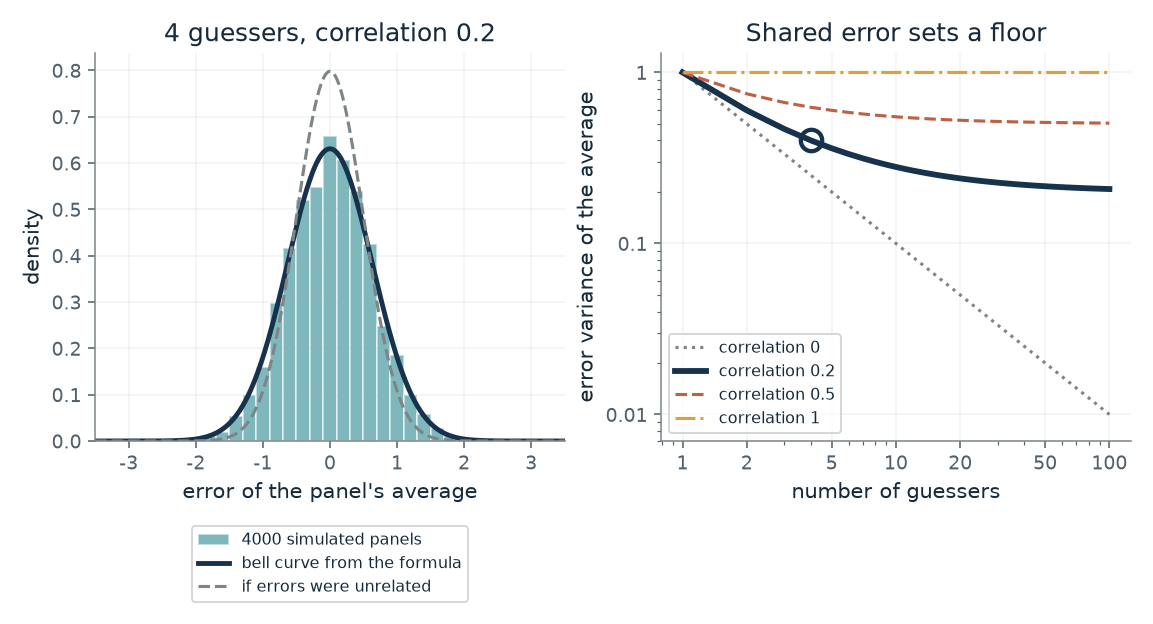

- **Variance of the average:** 0.4
- **Variance if errors were unrelated:** 0.25
- **Floor, however many are added:** 0.2
- **Simulated variance (4000 panels):** 0.39

With 4 guessers, each with error variance 1 and pairwise error correlation 0.2, the average has error variance 0.4, against 0.25 if the errors were unrelated. Adding guessers can never take it below 0.2.

Var = sigma^2 x ((1 - rho)/n + rho) = ((1 - 0.2)/4 + 0.2) = 0.4. Unrelated errors: 1/4 = 0.25. Floor = rho = 0.2. The simulation (seed 2342) built each error from a shared part and a private part and gave 0.39.

In [2]:
figure, values, explanation = average_picture(**{'n': 4, 'rho': 0.2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How steady is an average when the guessers share a lean?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of guessers = 4, Error correlation (rho) = 0.2: The average's error variance is 0.4: the unshared part, 0.8 divided by 4, is 0.2, and the shared part adds 0.2 more. With unrelated errors it would be 0.25. Slide n up: the curve flattens at 0.2, the floor.

**Takeaway:** Averaging removes only the part of the error that guessers do not share; the shared part survives any headcount.

**Why it matters:** A panel that looks large can behave like a small one. Knowing the floor tells you when to stop adding look-alike members and look for a different source.

**In brains and behavior:** Nerve cells that respond to the same thing share some of their random noise, and a 1994 study reported a weak average correlation of 0.12 between pairs. The formula is a way to think about what that does to a pool; it is a model, and the study was not about judgment.

**In machines:** An ensemble average can be computed exactly given error variances and a correlation. The correlation of real models' errors still has to be measured, and the chapter says none of the studies did that.

**Where it applies:** Equal weights, equal error variance, one pairwise correlation for all pairs, and no shared bias. The formula is about variance only: a lean that every member shares in the same direction is an extra problem it does not count.

**Check your understanding:** With 4 guessers and correlation 0.5, what is the error variance of the average, and what is the floor?

<details><summary>Show the answer</summary>

(1 - 0.5)/4 + 0.5 = 0.125 + 0.5 = 0.625. The floor is the correlation itself, 0.5. Unrelated errors would give 0.25.

</details>

*Source: Chapter 23, In an invented ledger, a small shared lean makes 787 guesses worth only 45. Book formula. The panel of four with correlation 0.2 giving 0.4 against 0.25 is the chapter's constructed example. The histogram is a seeded simulation (4000 panels) built to have exactly the stated correlation; it checks the formula and is not a measurement of any crowd.*

## C23-D02: How many independent guessers is a crowd worth?

If 787 guessers share a small error correlation of 0.021, how many independent guessers do they equal, and what happens when a thousand more join?

The variance of an average is sigma squared times (1 - rho)/n plus rho. An average of n independent guessers has variance sigma squared over n, so setting the two equal gives n_eff. As n grows, the first piece vanishes and only the floor rho remains, so the worth cannot exceed 1 over rho.

$$
n_{\mathrm{eff}}=\frac{n}{1+(n-1)\rho},\qquad \lim_{n\to\infty} n_{\mathrm{eff}}=\frac{1}{\rho}
$$

**Symbols:** n: the number of guessers; rho: the error correlation between any two guessers; here a chosen value; n_eff: effective panel size: how many independent guessers give an average as steady as the panel's; 1/rho: the ceiling the effective size approaches as the panel grows; undefined when rho is 0

**Predict before looking:** With correlation 0.021, predict the effective size of 787 guessers, and whether adding a thousand more would roughly double it.

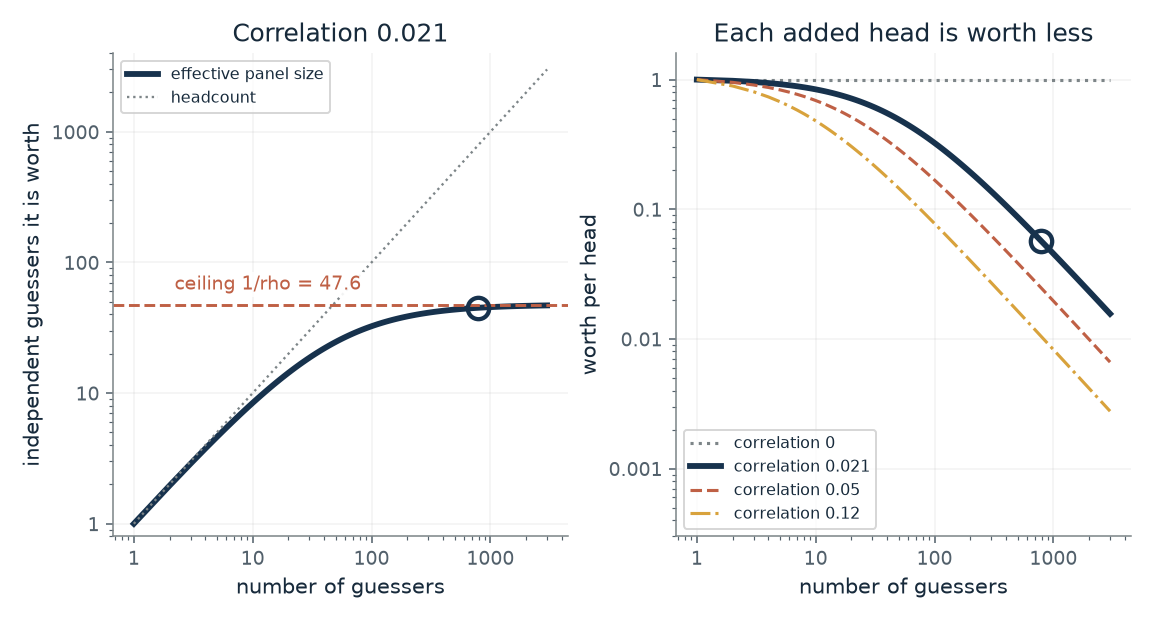

- **Effective panel size:** 45
- **Ceiling as the panel grows:** 47.6
- **Worth per head:** 0.0571
- **Variance of the average (sigma^2 = 1):** 0.0222

787 guessers whose errors correlate at 0.021 are worth 45 independent ones, or 0.0571 of a head each. No panel of this kind can be worth more than 47.6.

n_eff = n/(1 + (n - 1) rho) = 787/(1 + 786 x 0.021) = 787/17.5 = 45. Ceiling = 1/rho = 47.6.

In [3]:
figure, values, explanation = effective_picture(**{'n': 787, 'rho': 0.021})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many independent guessers is a crowd worth?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of guessers = 787, Error correlation (rho) = 0.021: 787 guessers are worth 45.0, about 45. Switch n to 1787 and the worth only rises to 46.4, because the ceiling is 1/0.021, about 48.

**Takeaway:** A large panel with even a small shared error is worth far fewer heads than its count, and the worth stalls at 1 divided by the correlation.

**Why it matters:** Headcounts and ensemble sizes overstate what a pool knows when members share influences. Estimating how much their mistakes overlap is the number that matters.

**In brains and behavior:** A 1994 study reported weak correlated noise between pairs of cells, averaging 0.12, and argued it can limit what a pool can signal; a 2020 study reported correlated noise limiting signalling in groups of 800 to 1,300 mouse visual cells. Applying one equal correlation to every pair is an idealization, not what those studies fitted.

**In machines:** For an ensemble, the formula turns a stated error correlation into a worth. The correlation of real models' errors is not supplied by any study in the chapter.

**Where it applies:** Equal error variance, one correlation for every pair, equal weights. The effective size counts steadiness only. It is not a measure of shared bias or of how many distinct opinions there are.

**Check your understanding:** Using n = 100 and correlation 0.05, what is the effective size, and what is the ceiling?

<details><summary>Show the answer</summary>

100/(1 + 99 x 0.05) = 100/5.95 = 16.8. The ceiling is 1/0.05 = 20.

</details>

*Source: Chapter 23, In an invented ledger, a small shared lean makes 787 guesses worth only 45. Book formula. The 787 guessers are Galton's count, but the correlation 0.021 is chosen by the chapter and nothing about Galton's guessers supports it. The values 0.05 and 0.12 are added here for contrast; 0.12 is the weak average correlation between pairs of nerve cells that a 1994 study reported, used as an idealization with every pair equal.*

## C23-D03: Which average survives a few wildly wrong guesses?

When a few guesses are off by a whole size class, how far does the plain average move compared with the median and the geometric mean?

A plain average adds the guesses, so a single guess a thousand times too big contributes a thousand times too much. The median looks only at the middle guess, so it changes only if the outliers cross the middle. The geometric mean averages the logs, so a factor of 100 adds only the log of 100 to one term.

$$
\bar g=\exp\!\Big(\frac{1}{n}\sum_{i=1}^{n}\ln x_i\Big)
$$

**Symbols:** x_i: guess number i, positive; n: the number of guesses (144 here); g-bar: the geometric mean: the plain average of the logs, turned back into a count

**Predict before looking:** If 5 percent of 144 guesses are 100 times too large, predict whether the arithmetic mean ends up within 20 percent of the true count or several times above it.

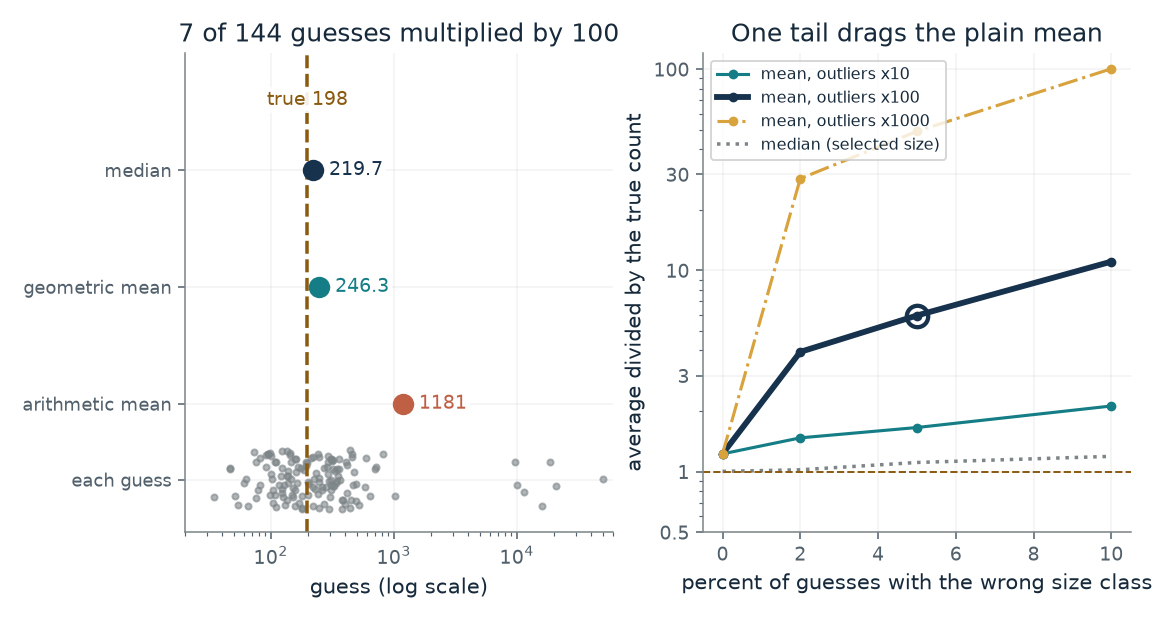

- **Arithmetic mean:** 1181
- **Geometric mean:** 246.3
- **Median:** 219.7
- **True count:** 198

With 7 of 144 constructed guesses multiplied by 100, the arithmetic mean is 1181, 5.96 times the true 198. The geometric mean, 246.3, and the median, 219.7, move much less.

Bulk: 144 guesses with log10 normal, center log10(190), sd 0.3 (seed 2011). The first 7 are multiplied by 100. Geometric mean = exp(mean of ln guesses) = 246.3. Mean 1181, median 219.7.

In [4]:
figure, values, explanation = average_choice_picture(**{'fraction': 0.05, 'factor': 100})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Which average survives a few wildly wrong guesses?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of guesses in the wrong size class = 0.05, How far off those guesses are (times) = 100: Seven guesses 100 times too large lift the arithmetic mean from 242 to 1181, about 6.0 times the true 198, while the geometric mean moves only from 197 to 246 and the median from 198 to 220.

**Takeaway:** One long tail of guesses in the wrong size class drags a plain average up without limit, while a median and a geometric mean react far less.

**Why it matters:** Pooling rules are decisions about the shape of the errors. A machine applies any rule exactly the same way each time, so choosing the rule is the part a person still owns.

**Where it applies:** The bulk of guesses is unbiased in logs and the outliers are a pure multiple of the bulk. Real guesses will not split so cleanly. Which average is best depends on the shape of the errors, and no rule is best for all shapes.

**Check your understanding:** In a group of 4 guesses 100, 100, 100 and 10,000, what are the arithmetic mean and the geometric mean?

<details><summary>Show the answer</summary>

Arithmetic mean = 10,300/4 = 2,575. Geometric mean = (100 x 100 x 100 x 10,000)^(1/4) = (10^10)^(1/4) = 10^2.5, about 316. The median is 100.

</details>

*Source: Chapter 23, Guessing Swiss murders, alone and in sight of others. Constructed sample, not the students' data. The question (198 murders registered in Switzerland in 2006) and the group of 144 follow the chapter's account of Lorenz and colleagues, who reported a mean of 838, a median of 170 and a geometric mean of about 174 on first guesses. Here 144 guesses are drawn with seed 2011 around 190, and some are multiplied by 10, 100 or 1000 to imitate a wrong size class.*

## C23-D04: Why can social influence narrow a crowd without making it more right?

If every member moves part of the way to the crowd's average, what happens to the crowd's own error and to the members' average error?

Average squared miss equals the squared miss of the crowd average plus the average squared distance of members from that average. Moving each member a fixed fraction toward the average leaves the average where it was and scales every distance from it by one minus the fraction. So the second piece shrinks while the first stays.

$$
\frac{1}{n}\sum_{i}(y_i-t)^2=(\bar y-t)^2+\frac{1}{n}\sum_{i}(y_i-\bar y)^2
$$

**Symbols:** y_i: member i's guess on the log scale; y-bar: the crowd average of the logs, which is the geometric mean on the original scale; t: the true value on the log scale; n: the number of members (12 here)

**Predict before looking:** If every member moves half the way to the crowd average three times, predict whether the crowd's own squared miss changes and by what factor the disagreement shrinks.

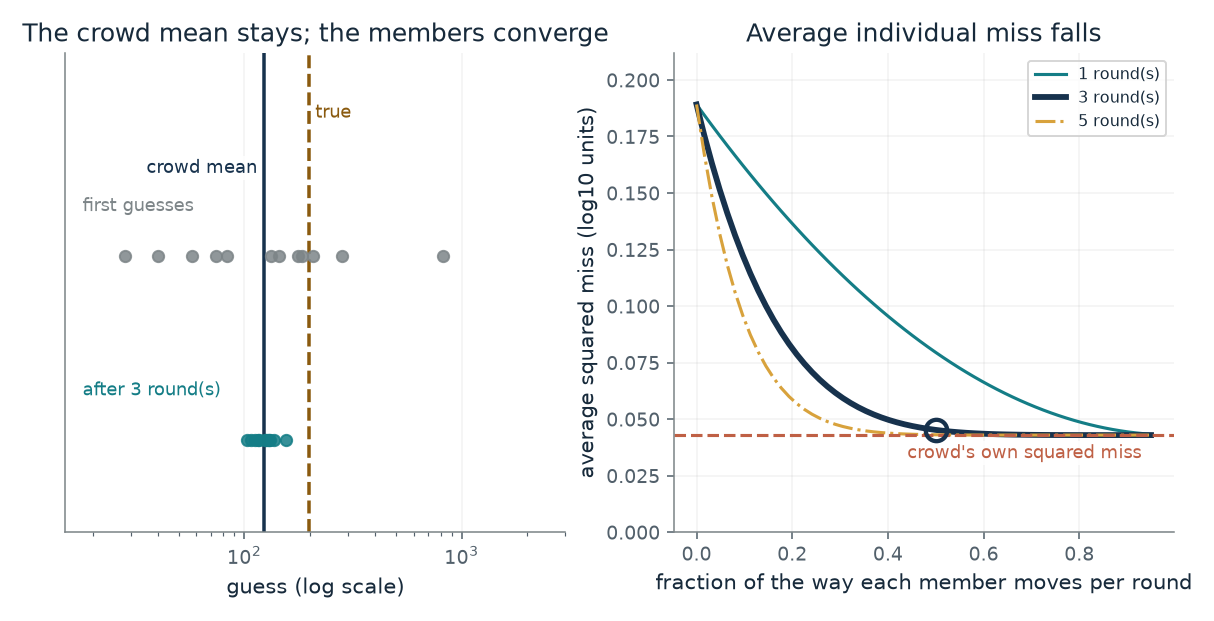

- **Average individual squared miss, before:** 0.189
- **Average individual squared miss, after:** 0.0452
- **Crowd's squared miss (unchanged):** 0.0429
- **Disagreement among members, after:** 0.00228

Each of 12 constructed guessers moves 0.5 of the way to the group's log average, 3 time(s). The average squared miss falls from 0.189 to 0.0452, while the crowd's own squared miss stays 0.0429.

Average squared miss = crowd's squared miss + disagreement. Before: 0.189 = 0.0429 + 0.146. After: 0.0452 = 0.0429 + 0.00228. Disagreement shrinks by (1 - 0.5)^6 = 0.0156. Logs are base 10; seed 2012.

In [5]:
figure, values, explanation = pull_picture(**{'pull': 0.5, 'rounds': 3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why can social influence narrow a crowd without making it more right?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Fraction moved toward the crowd each round = 0.5, Rounds of influence = 3: The crowd's squared miss stays put while the average individual squared miss falls from 0.189 to 0.045, because disagreement shrinks by a factor of (0.5)^6, about 0.0156.

**Takeaway:** The members' average miss splits into the crowd's own miss plus their disagreement. Pulling toward the average removes only the disagreement.

**Why it matters:** A group that becomes more alike can look more accurate member by member while knowing exactly as much as before. Diversity is what pooling uses, and influence uses it up.

**Where it applies:** Every member moves the same fraction toward the current crowd average each round. The study found that guesses grew more alike and the crowd's error did not fall significantly in its main test. This computation shows why those can go together; it does not fit the students' revisions.

**Check your understanding:** Two guesses on the log scale are 1 and 3, and the truth is 3. They each move halfway to their average once. What are the average squared miss before and after?

<details><summary>Show the answer</summary>

Before: (4 + 0)/2 = 2. The average is 2, so after one round they sit at 1.5 and 2.5, giving (2.25 + 0.25)/2 = 1.25. The crowd's own squared miss is (2 - 3)^2 = 1 both times, and the disagreement falls from 1 to 0.25.

</details>

*Source: Chapter 23, Guessing Swiss murders, alone and in sight of others. Book identity (stated on logs). The 12 guesses are constructed with seed 2012 (a low lean of 0.25 in log10 units and spread 0.4), and the pull rule is the chapter's simple model of moving the same part of the way to the crowd average. The chapter says the study did not fit this rule to the students.*

## C23-D05: What does an independent check add that a tenth look-alike cannot?

For nine models with error variance 1 and error correlation 0.4, what does a tenth similar model buy, and what does an independent check buy?

The panel average cannot fall below the shared error rho, so adding a similar member moves it only a little. An independent source has no part in that shared error, so combining by precision (one over variance) pulls the answer below the floor of the panel alone. The combined precision is the sum of the two precisions.

$$
V_{\text{panel}}=\frac{1-\rho}{n}+\rho,\qquad V_{\text{with check}}=\frac{1}{1/V_{\text{panel}}+1/V_{\text{check}}}
$$

**Symbols:** n: the number of models in the panel; rho: the error correlation between any two panel members, chosen here; V_panel: error variance of the panel's average, each member having variance 1; V_check: error variance of an unbiased check whose errors are unrelated to the panel's

**Predict before looking:** Before moving the sliders, predict whether a tenth model like the other nine lowers the panel's variance by more or less than one percent of a unit.

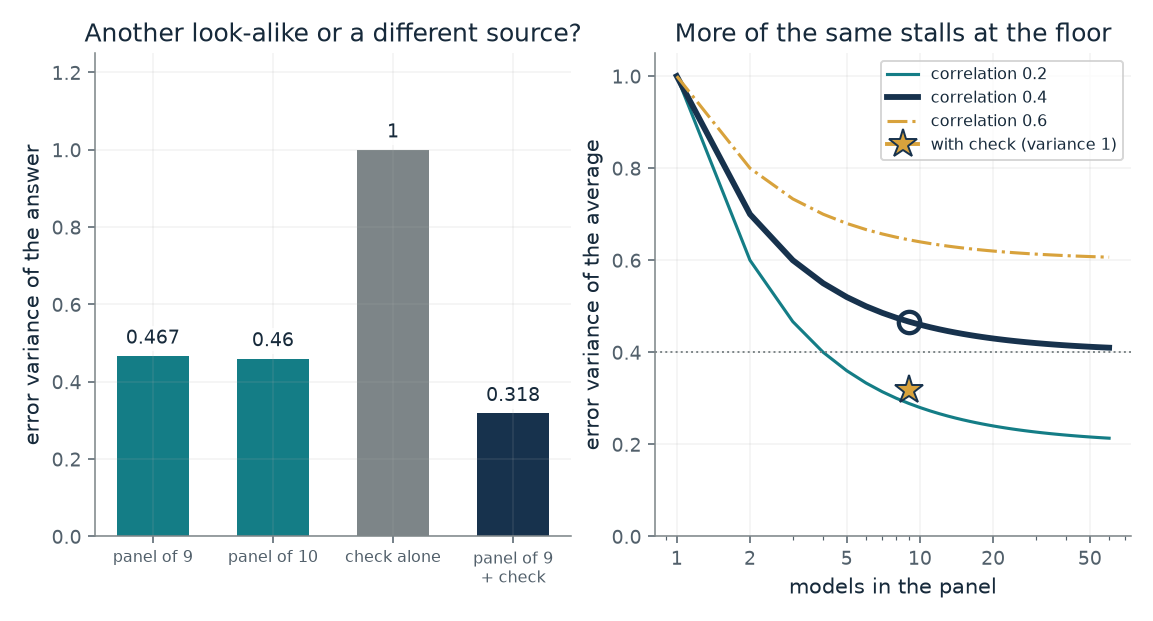

- **Panel of 9:** 0.467
- **Panel of 10:** 0.46
- **Panel plus independent check:** 0.318
- **Weight on the check:** 0.318

A panel of 9 with error variance 1 and correlation 0.4 averages to variance 0.467, and a panel of 10 only to 0.46. An independent check of variance 1, weighted by precision, takes it to 0.318.

Panel: (1 - 0.4)/9 + 0.4 = 0.467. One more member: (1 - 0.4)/10 + 0.4 = 0.46. With the check: 1/(1/0.467 + 1/1) = 0.318. The check's errors must be unbiased and unrelated to the panel's.

In [6]:
figure, values, explanation = check_picture(**{'n': 9, 'rho': 0.4, 'check_var': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does an independent check add that a tenth look-alike cannot?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Models in the panel = 9, Error correlation among them = 0.4, Error variance of the independent check = 1.0: The panel of nine has variance 0.467 and a tenth member only 0.46, a gain of 0.007. An independent check of variance 1, weighted by precision, takes it to 0.318.

**Takeaway:** Once members share error, the next look-alike barely helps, while one source with independent errors can help a lot even if it is individually no better.

**Why it matters:** The useful question for a partnership is where each answer came from, not only how reliable it seems. A source that fails for different reasons is worth more than another copy of the same reason.

**In brains and behavior:** In Bahrami and colleagues' 2010 contrast-test pairs, partners with similar sensitivity beat their better member, and very unequal pairs could lose. The model that fit was weighted confidence sharing, and the pairs pooled less well than an ideal inverse-variance rule would. Those are behavioral results from 15 pairs in the first experiment.

**In machines:** An ensemble plus a verifier can be combined by inverse-variance weighting if the verifier's errors are independent of the ensemble's. The chapter's nine models and their variances are invented.

**Where it applies:** All estimates are unbiased for the same quantity, the check's errors are independent of the panel's, and the weights use the true variances. If the check shares the panel's sources or any source is biased, the combined variance is not what the formula gives.

**Check your understanding:** A panel has variance 0.5 and an independent check has variance 0.5. What is the combined variance?

<details><summary>Show the answer</summary>

Precisions are 2 and 2, which add to 4, so the variance is 1/4 = 0.25.

</details>

*Source: Chapter 23, Two heads in a contrast test: similar partners gained, very unequal pairs could lose. Chapter's constructed example (nine models, variance 1, correlation 0.4, giving about 0.47, then about 0.32 with a check), computed here with extra panel sizes and correlations. The numbers are invented, as the chapter says.*

## C23-D06: Can independent models agree on a wrong answer by temptation alone?

If two models never see each other's answers but one wrong option tempts both, how often do they pick the same wrong option?

Two independent choosers match when both land on the same option. Their match chance is the sum, over options, of the product of the two shares. With uniform shares over three options this is 3 times (1/3)^2 = 1/3. Concentrating the shares on one option raises the sum. If the two models are tempted by different options, the sum is smaller.

$$
P(\text{match})=\sum_{j}p_j\,q_j
$$

**Symbols:** p_j: model 1's chance of choosing wrong option j, given it is wrong; q_j: model 2's chance of choosing wrong option j, given it is wrong; L: the share of wrong answers going to the most tempting option; the other two options share the rest equally

**Predict before looking:** If the single most tempting wrong option draws 60 percent of each model's wrong answers, predict whether independent models would match about 0.4, 0.5 or 0.6 of the time.

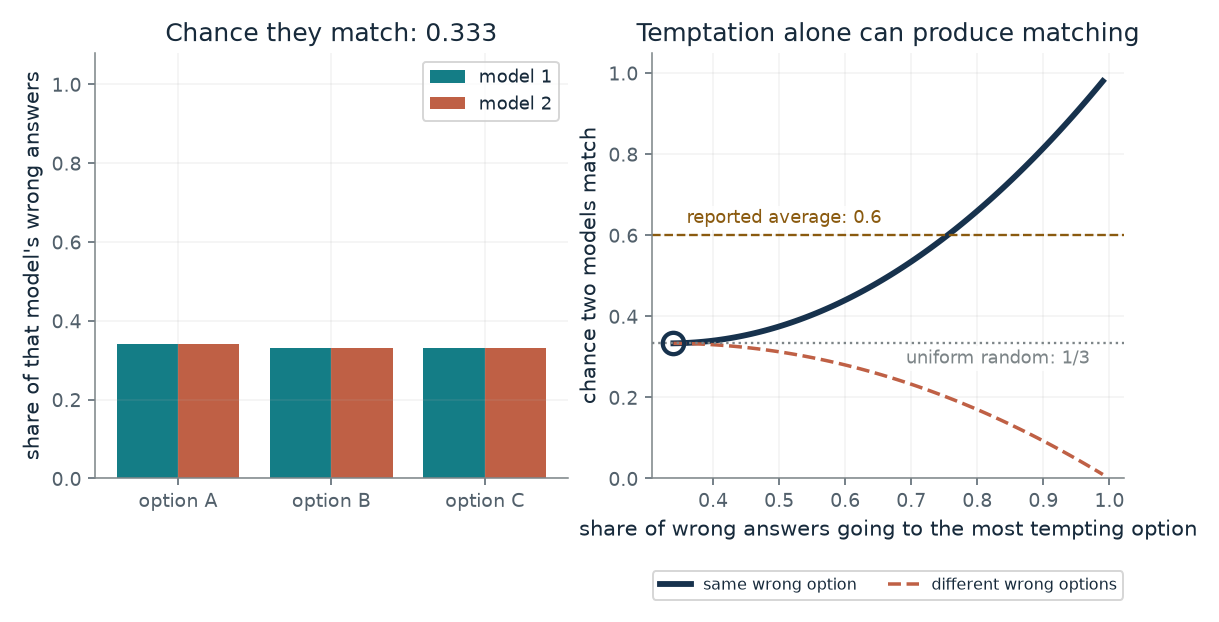

- **Chance two independent models match:** 0.333
- **Uniform random baseline:** 0.333
- **Average the study reported over model pairs:** 0.6
- **Most tempting share needed to reach 0.6 (same option):** 0.755

If independent models send 0.34 of their wrong answers to their most tempting option, and the same option tempts both models, they match 0.333 of the time. Reaching the reported 0.6 this way takes a share of 0.755 on one shared option.

Match chance = sum over options of (model 1's share) x (model 2's share) = 0.34 x 0.34 + 2 x 0.33^2 = 0.333. For the same option, L^2 + (1 - L)^2/2 = 0.6 gives L = (1 + sqrt(1.6))/3 = 0.755.

In [7]:
figure, values, explanation = same_wrong_picture(**{'lure': 0.34, 'lures': 'same wrong option'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Can independent models agree on a wrong answer by temptation alone?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of wrong answers on the most tempting option = 0.6, Which option tempts the second model = same wrong option: With 0.6 of wrong answers on one shared option, independent models match 0.6 x 0.6 + 2 x 0.2 x 0.2 = 0.44 of the time, well above 1/3 and still below the reported 0.6. It takes a share of about 0.755 to reach 0.6.

**Takeaway:** Agreement on wrong options is not proof that models copy each other: shared temptation produces it with no communication.

**Why it matters:** Voting and averaging assume independence. Matching on wrong answers is a warning for that assumption, but this figure cannot be dropped into the error-correlation formula, and why it arises is not established.

**In machines:** The study compared 71 models on a public leaderboard and found higher matching for models from the same developer and for larger, more accurate ones. The chapter says why this happens is not established.

**Where it applies:** Both models choose independently and each has the same fixed shares over three wrong options. The chapter notes that some wrong options look closer to right and would draw independent models too, so the gap above 1/3 does not by itself measure excess agreement. The 0.6 is an average over pairs, not an error correlation.

**Check your understanding:** If 0.5 of each model's wrong answers go to the same option and the other two share the rest, what is the match chance?

<details><summary>Show the answer</summary>

The other shares are 0.25 each. Match = 0.5 x 0.5 + 0.25 x 0.25 + 0.25 x 0.25 = 0.25 + 0.0625 + 0.0625 = 0.375.

</details>

*Source: Chapter 23, Models that pick the same wrong option. Constructed illustration. The reported figures are from Kim and colleagues as the chapter gives them: an average match of 0.6 over pairs among 71 models on questions both got wrong, against 1/3 for uniform random choice among three wrong options. The shape of the wrong-option shares here is invented to show a mechanism, not fitted to their data.*

## C23-D07: When does a majority vote over sampled answers help?

If a model samples many chains of reasoning and the most common answer wins, when does the vote beat one chain, and when does it make things worse?

For one question with chain chance p, the vote is right when more than half of the chains are. For p above one half the chance climbs toward 1 as chains are added, and for p below one half it falls toward 0. The overall effect is the average across questions, so it depends on how many questions lean each way.

$$
P(\text{vote right})=\sum_{k>m/2}\binom{m}{k}\,p^{k}(1-p)^{m-k}
$$

**Symbols:** m: the number of sampled chains, odd so there are no ties; p: the chance one chain is right on this question; k: how many of the m chains are right

**Predict before looking:** If a hard question has a chain chance of 0.3, predict whether a vote of 41 chains on it is right more often or less often than one chain.

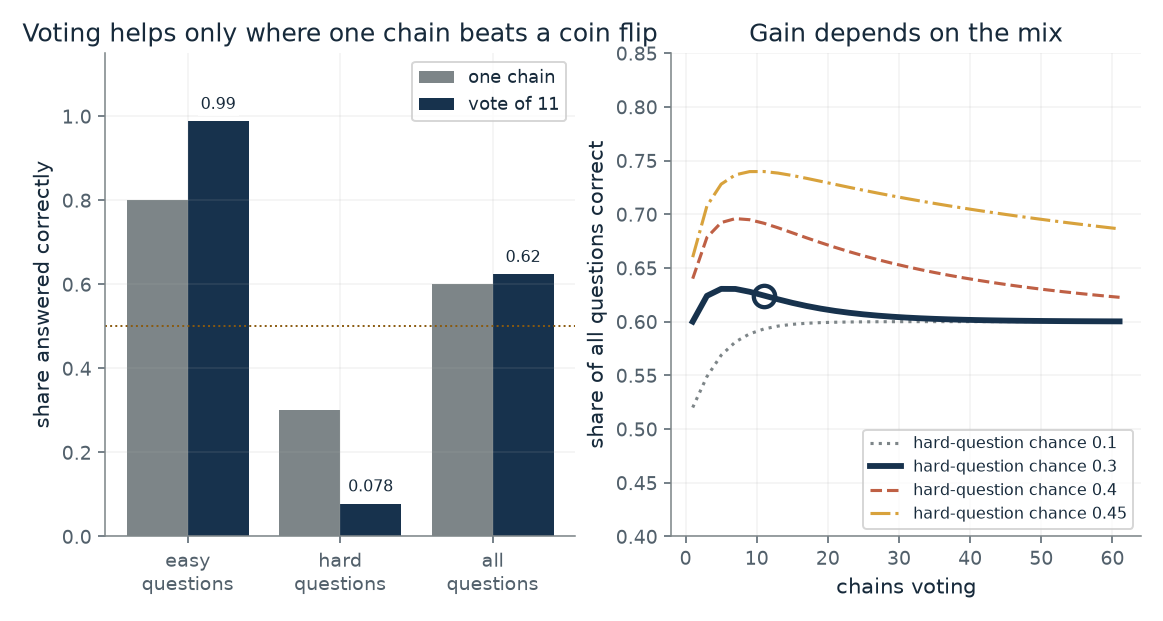

- **One chain, all questions:** 0.6
- **Vote of 11, all questions:** 0.624
- **Vote on hard questions:** 0.0782
- **Change from voting:** 0.0243

In a constructed mix with 60 percent easy questions (each chain right with chance 0.8) and hard ones (chance 0.3), one chain scores 0.6 and a vote of 11 scores 0.624. Voting lifts easy questions toward certainty and sinks hard ones.

Vote correct = sum over k above 11/2 of C(11, k) p^k (1 - p)^(11 - k). Easy: 0.988. Hard (p = 0.3): 0.0782. Overall = 0.6 x 0.988 + 0.4 x 0.0782 = 0.624; one chain: 0.6 x 0.8 + 0.4 x 0.3 = 0.6.

In [8]:
figure, values, explanation = vote_picture(**{'chains': 11, 'hard_chance': 0.3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When does a majority vote over sampled answers help?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chains voting = 41, Chance one chain is right on a hard question = 0.3: On hard questions a vote of 41 is right only 0.004 of the time, against 0.3 for one chain, while easy questions rise to 1.000. Overall the vote scores 0.601 against 0.60 for one chain. With hard-question chance 0.45 the vote scores 0.704 against 0.660.

**Takeaway:** A vote pushes each question toward certainty in whichever direction a single chain already leans, so it helps only where chains are right more often than not.

**Why it matters:** Adding votes does not repair a model that gives the same wrong answer most of the time. The chapter's cross-model vote did worse than the best single model because lower-capacity models dragged it down.

**In machines:** Self-consistency samples several chains from one model and takes the most common final answer. The chains are independent draws for a given question yet still share that model's strengths and biases.

**Where it applies:** Chains are drawn independently given the question, each right with a fixed chance for that question, and wrong chains are treated as not forming a majority for the right answer. In real use all chains share one model's strengths and biases and wrong chains may agree with each other.

**Check your understanding:** With p = 0.6 on a question, what is the chance that a vote of 3 chains is right?

<details><summary>Show the answer</summary>

Right when at least 2 of 3 chains are right: 3 x 0.6^2 x 0.4 + 0.6^3 = 0.432 + 0.216 = 0.648.

</details>

*Source: Chapter 23, Models that pick the same wrong option. Constructed population, not a result. Easy questions (60 percent of them) have chain accuracy 0.8 and hard ones a chosen lower value. The chapter reports, for PaLM-540B on grade-school math, 56.5 percent with one chain and 74.4 percent with a vote over 40 chains (mean of 10 runs), and 36.9 percent when PaLM-540B and a smaller model voted together; this demonstration does not reproduce those figures.*

## Bring it to your own question

Ask for the guesses or scores, how each was produced, whether the members learned from the same sources, and how lopsided the errors look. Then pick the card: the variance formula and effective size for how much an average will vary, a median or geometric mean when a few guesses are wildly off, inverse-variance weighting when one source is independent of the rest, and a check on whether the vote's members share the same wrong answer. Report the pooled answer, the effective size under a stated correlation, and the assumption that would break it.

Use the `mmi-ch23-several-minds-help` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.